# IN2022_V06: full ADCP record and two candidate eddy visits

A simple first look: load **all rows**, plot the whole record, then extract two broad time windows from `info.md`. These are candidate visits, not confirmed eddy transects; mooring work and other ship activity may remain. Refine the UTC windows after comparing the tracks with your own OceanCurrent inspection. No LATTE fitting or background-current removal is performed here.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys
import importlib

# Works from this notebook folder or the repository root.
STUDY_DIR = Path.cwd()
if not (STUDY_DIR / 'inspection_tools.py').is_file():
    STUDY_DIR = STUDY_DIR / 'seacofs_eddy_tilt_analysis/observations/MNF_IN2022_V06_adcp_trawler'
if not (STUDY_DIR / 'inspection_tools.py').is_file():
    raise FileNotFoundError('Run from the notebook folder or the UNSW-PhD repository root.')
sys.path.insert(0, str(STUDY_DIR))
import inspection_tools as inspect
importlib.reload(inspect)

DATA_PATH = Path('/srv/scratch/z5297792/tilt_observation_data/MNF_IN2022_V06_adcp_trawler/MNF_IN2022_V06_adcp_trawler.csv')
# End times are exclusive; the first window includes all of 14–16 July.
WINDOWS = {
    'Visit 1: 14–16 July': ('2022-07-14T00:00:00Z', '2022-07-17T00:00:00Z'),
    'Visit 2: around 24 July': ('2022-07-23T00:00:00Z', '2022-07-26T00:00:00Z'),
}
MIN_ATTENDANCE = None  # Optional plot filter (%); None keeps all attendance values.
VELOCITY_LIMIT = 1.0   # Shared U/V colour limits (m/s).


## Load the whole CSV

This export contains literal `\r\n` sequences. Decode those line breaks before reading. `data` retains every exported row, with shorter column names and UTC timestamps. Both instruments remain separate; no QC meaning is inferred from the blank `Avg QC` field.


In [2]:
data = inspect.load_full_record(DATA_PATH)
print(f'{len(data):,} rows; {data.time.min()} to {data.time.max()}')
display(data.head())
display(data.groupby('instrument').agg(
    rows=('depth', 'size'), start_utc=('time', 'min'), end_utc=('time', 'max'),
    shallowest_m=('depth', 'min'), deepest_m=('depth', 'max'),
))
display(data[['time', 'lat', 'lon', 'depth', 'u', 'v', 'attendance', 'Avg QC']].isna().sum().rename('missing rows'))


195,006 rows; 2022-07-14 05:42:58+00:00 to 2022-07-27 20:50:46+00:00


,Survey,Datafile,time,lat,lon,Project,MARLIN,MARLIN UUID,Averaging Period (sec),U Ship (m/sec),V Ship (m/sec),Bottom Depth,depth,u,v,Avg QC,attendance,instrument
0,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:42:58+00:00,-26.76496,153.43286,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.62,-1.17,NaN,18.0,-0.108,-0.016,NaN,100,os150nb
1,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:42:58+00:00,-26.76496,153.43286,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.62,-1.17,NaN,26.0,-0.009,0.000,NaN,100,os150nb
2,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:42:58+00:00,-26.76496,153.43286,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.62,-1.17,NaN,34.0,0.002,-0.056,NaN,100,os150nb
3,IN2022_V06,in2022_v06_ADCP_pt1_os75nb.nc,2022-07-14 05:43:00+00:00,-26.76499,153.43301,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.60,-1.16,NaN,30.0,-0.004,-0.007,NaN,84,os75nb
4,IN2022_V06,in2022_v06_ADCP_pt1_os150nb.nc,2022-07-14 05:47:58+00:00,-26.76803,153.44934,Data Acquisition and Processing,NaN,6d0b2e74-8474-4e30-9d3c-4969105b1488,NaN,5.47,-1.12,NaN,18.0,-0.143,0.005,NaN,100,os150nb


,rows,start_utc,end_utc,shallowest_m,deepest_m
instrument,,,,,
os150nb,97257,2022-07-14 05:42:58+00:00,2022-07-27 20:50:46+00:00,17.9,346.0
os75nb,97749,2022-07-14 05:43:00+00:00,2022-07-27 18:00:46+00:00,30.0,750.0


time               0
lat                0
lon                0
depth              0
u                  0
v                  0
attendance         0
Avg QC        195006
Name: missing rows, dtype: int64

## Plot the whole record

Track points are reduced to one position per instrument/time so depth bins do not duplicate the track. Velocity panels show individual time–depth samples, with no interpolation across gaps. All depths are shown. Colour limits clip the displayed colours only; values in `data` are unchanged. An optional attendance threshold affects velocity plots only.


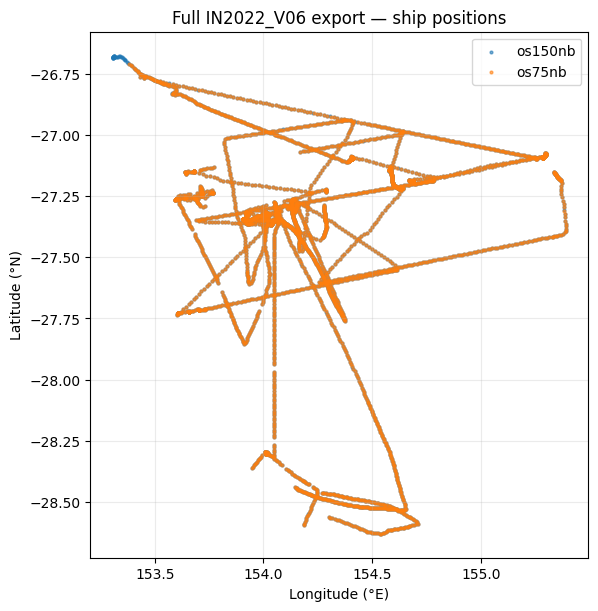

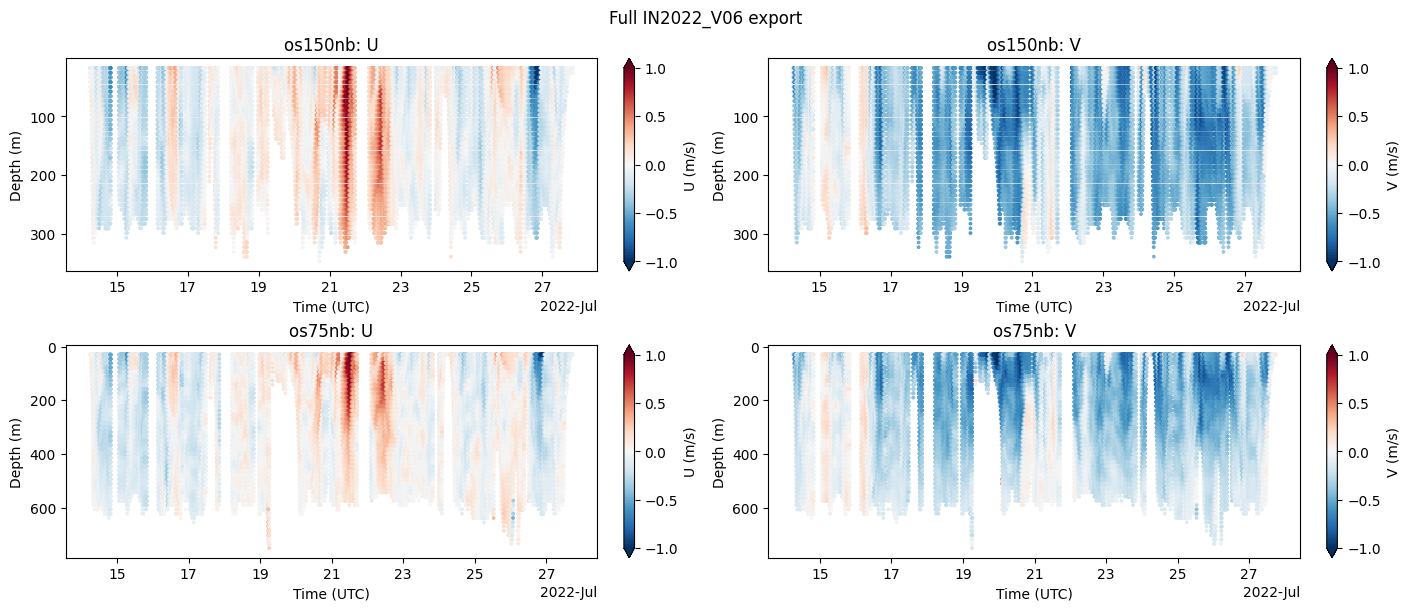

In [3]:
inspect.plot_record(data, 'Full IN2022_V06 export',
                    min_attendance=MIN_ATTENDANCE, velocity_limit=VELOCITY_LIMIT)


## Choose a time and ADCP window

Choose the UTC centre time and total ADCP window below, then run the next cell. Missing daily OceanCurrent maps are downloaded automatically from AODN and cached beside the ADCP CSV. Later calls reuse these files. Internet access is needed only for missing files.

An exact daily map is used when available; otherwise GSLA and total geostrophic velocity are linearly interpolated between surrounding daily maps. The background is a snapshot at the centre time, not an average over the ADCP window. Source times appear on the plot. All ADCP depths and instruments in the window are returned as `selected`.


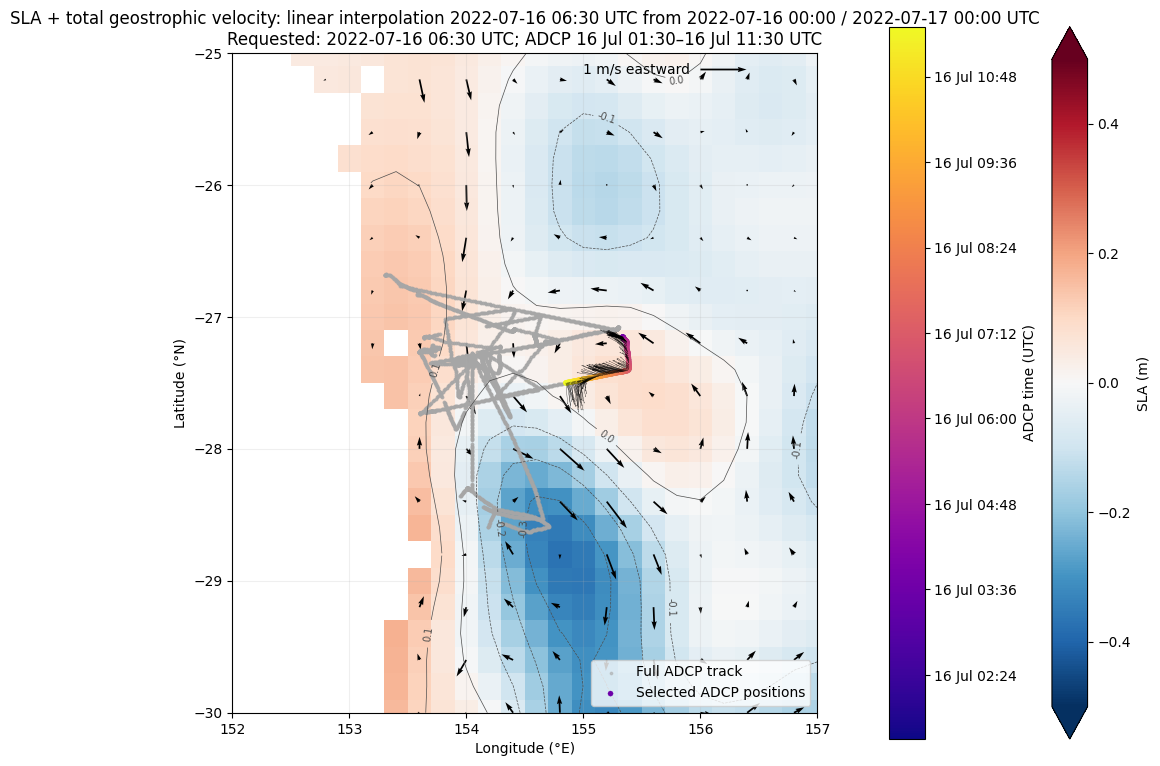

6,657 ADCP rows in [2022-07-16 01:30:00+00:00, 2022-07-16 11:30:00+00:00); linear interpolation 2022-07-16 06:30 UTC from 2022-07-16 00:00 / 2022-07-17 00:00 UTC


In [14]:
TIME_UTC = '2022-07-16T06:30:00Z'
ADCP_WINDOW_HOURS = 10  # Total width: ADCP_WINDOW_HOURS//2 hours either side.
ax, selected = inspect.inspect_time(
    data, DATA_PATH.parent, TIME_UTC, window_hours=ADCP_WINDOW_HOURS, quiv_scale=10, quiv_width=.0005
)

ORIGIN_LON_LAT = (155.1, -27.5)  # Optional (longitude, latitude) ADCP-based centre guess.
ax.scatter(*ORIGIN_LON_LAT, zorder=20, marker='x', color='magenta',s=50)


## LATTE through the selected ADCP window

Use `selected` from the inspection cell above, unchanged in time and geographic extent. The OceanCurrent map is context only: LATTE fits **ADCP velocities alone** at each measured depth. The shallowest selected ADCP positions supply a reproducible starting *guess* (their median), which you can override below. Accepted inner centres and ellipses seed the next depth; rejected depths stay in the table and do not update the seed. A surface rejection means there is no supported surface-to-depth centreline for this selection.

Selected 6,657 rows at 74 measured depths; 6,657 finite rows used. Origin: (155.1, -27.5).


,rows,times,shallowest_m,deepest_m
instrument,,,,
os150nb,3179,96,18.0,298.0
os75nb,3478,96,30.0,622.0


path                 /home/z5297792/ESP_zonodo/functions.py
sha256    8e4b06fe4c144f7a70671ee913b6d27784f9cdb587e9b0...
Name: ESP backend, dtype: object

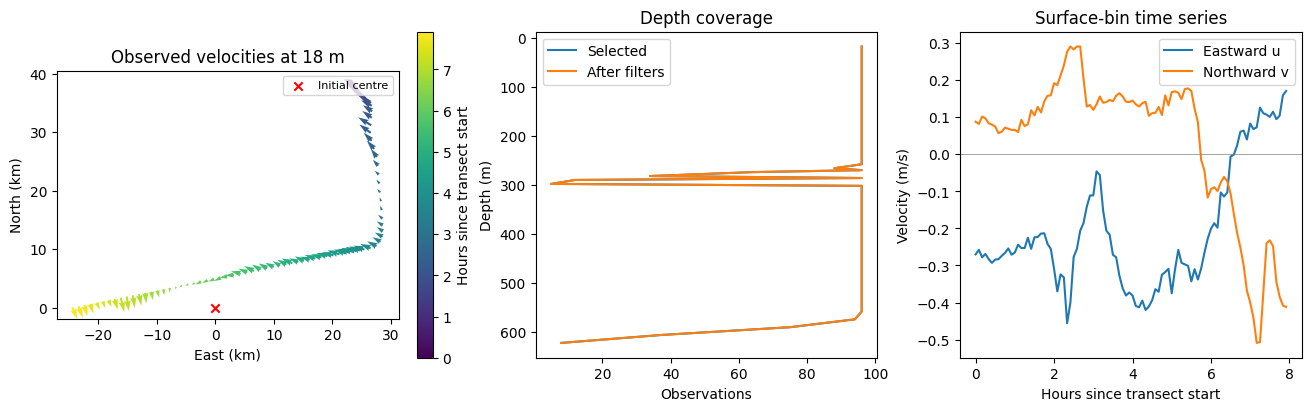

In [6]:
import importlib.util

OBSERVATIONS_DIR = STUDY_DIR.parent
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)
BACKEND_PATH = Path("/home/z5297792/ESP_zonodo/functions.py")

# ORIGIN_LON_LAT = (155.1, -27.5)  # Optional (longitude, latitude) ADCP-based centre guess.
FIT_MIN_ATTENDANCE = None  # Separate from the earlier plot-only MIN_ATTENDANCE.
FIT = dict(core_radius=50_000., outer_radius=150_000.,
           max_centre_step=35_000., radius_limit=100_000.,
           min_core_points=8, min_outer_points=12,
           expected_sign=1, require_peak_bracket=True)  # Southern Hemisphere AE
MAP_DEPTHS = (18, 100, 200, 300)
HALF_WIDTH_KM = 120

surface_obs = selected.loc[selected.depth.eq(selected.depth.min())]
if ORIGIN_LON_LAT is None:
    ORIGIN_LON_LAT = (float(surface_obs.lon.median()), float(surface_obs.lat.median()))
lon0, lat0 = ORIGIN_LON_LAT
finite = selected.time.notna() & np.isfinite(selected[["lon", "lat", "depth", "u", "v"]]).all(axis=1)
if FIT_MIN_ATTENDANCE is not None:
    finite &= selected.attendance.ge(FIT_MIN_ATTENDANCE)
fit_data = selected.loc[finite].sort_values(["depth", "time"]).copy()
if fit_data.empty or fit_data.duplicated(["time", "depth"]).any():
    raise ValueError("No usable ADCP data, or duplicate time/depth bins across instruments.")
fit_data["x"] = (fit_data.lon - lon0) * 111000 * np.cos(np.deg2rad(lat0))
fit_data["y"] = (fit_data.lat - lat0) * 111000
coverage = selected.groupby("depth").size().rename("n_selected").to_frame()
coverage["n_used"] = fit_data.groupby("depth").size().reindex(coverage.index, fill_value=0)
backend, backend_info = esp.load_backend(BACKEND_PATH)
print(f"Selected {len(selected):,} rows at {len(coverage)} measured depths; "
      f"{len(fit_data):,} finite rows used. Origin: {ORIGIN_LON_LAT}.")
display(fit_data.groupby("instrument").agg(
    rows=("depth", "size"), times=("time", "nunique"),
    shallowest_m=("depth", "min"), deepest_m=("depth", "max")))
display(pd.Series(backend_info, name="ESP backend"))
esp.plot_sampling(fit_data, coverage, half_width_km=HALF_WIDTH_KM)
plt.show()

## Fit from shallow to deep

The inner fit uses observations within the editable 35 km elliptical core, selected twice at each depth. The Gaussian stage uses the 100 km outer selection and the anticyclonic circulation-sign filter. A failed ellipse, large centre jump or unsupported Gaussian radius remains a rejected row; the method does not invent a reconstruction at that level.

In [7]:
results, samples = esp.fit_depths(
    fit_data, backend, "LATTE", depth_levels=coverage.index, **FIT)
esp.report(results)
SURFACE_FIT_OK = bool(results.inner_valid.iloc[0])
if not SURFACE_FIT_OK:
    print("Shallowest LATTE inner fit rejected: there is no validated surface-anchored trajectory. "
          "Review the chosen ADCP window and centre guess before interpreting deeper fits.")
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "core_spread_ratio", "candidate_min_eigenvalue", "inner_R2", "Rc_m", "vector_R2"]
with pd.option_context("display.max_rows", 80):
    display(results[columns].round(4))

LATTE: 2/74 accepted inner fits; 0/74 accepted Gaussian reconstructions.
status
centre_jump                  25
insufficient_observations     1
insufficient_outer            1
invalid_ellipse              46
outer_radius_limit            1
Centre offsets reference the shallowest accepted fit: 606 m.
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.
Shallowest LATTE inner fit rejected: there is no validated surface-anchored trajectory. Review the chosen ADCP window and centre guess before interpreting deeper fits.


,depth_m,status,n_obs,n_core,inner_valid,valid,core_spread_ratio,candidate_min_eigenvalue,inner_R2,Rc_m,vector_R2
0,18.0,invalid_ellipse,96,96,False,False,0.3917,-0.3018,0.6064,NaN,NaN
1,26.0,invalid_ellipse,96,96,False,False,0.3917,-0.3882,0.5800,NaN,NaN
2,30.0,invalid_ellipse,96,96,False,False,0.3916,-0.5655,0.6056,NaN,NaN
3,34.0,invalid_ellipse,96,96,False,False,0.3917,-0.1475,0.6020,NaN,NaN
4,42.0,centre_jump,96,96,False,False,0.3917,0.1962,0.6211,NaN,NaN
5,46.0,invalid_ellipse,96,96,False,False,0.3916,-0.3661,0.6262,NaN,NaN
6,50.0,centre_jump,96,96,False,False,0.3917,0.3380,0.6245,NaN,NaN
7,58.0,centre_jump,96,96,False,False,0.3917,0.3511,0.6188,NaN,NaN
8,62.0,invalid_ellipse,96,96,False,False,0.3916,-0.3038,0.6213,NaN,NaN
9,66.0,centre_jump,96,96,False,False,0.3917,0.3529,0.6084,NaN,NaN


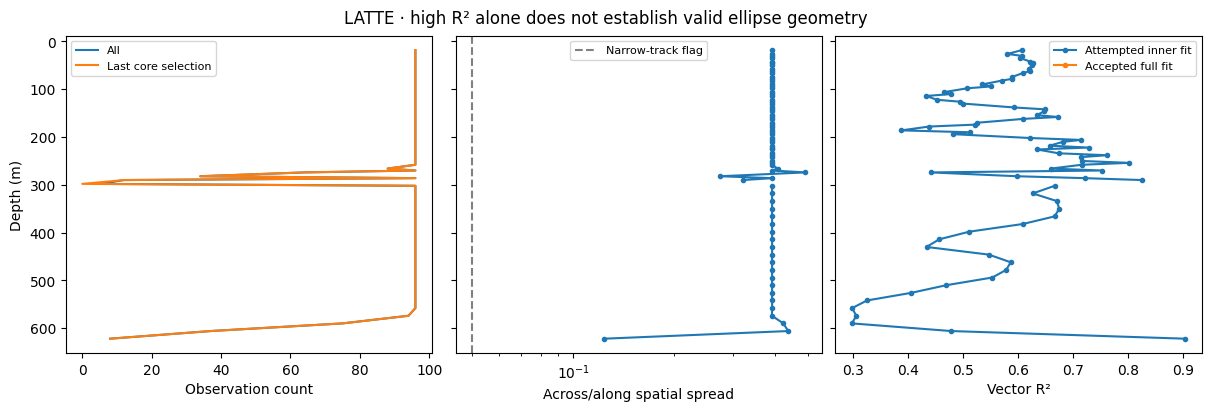

In [8]:
esp.plot_diagnostics(results)
plt.show()

## Centre trajectory and parameters

Offsets reference the shallowest **accepted** LATTE inner fit, if one exists. If the observed surface bin failed, isolated deeper estimates are diagnostics, not a surface-to-depth tilt measurement.

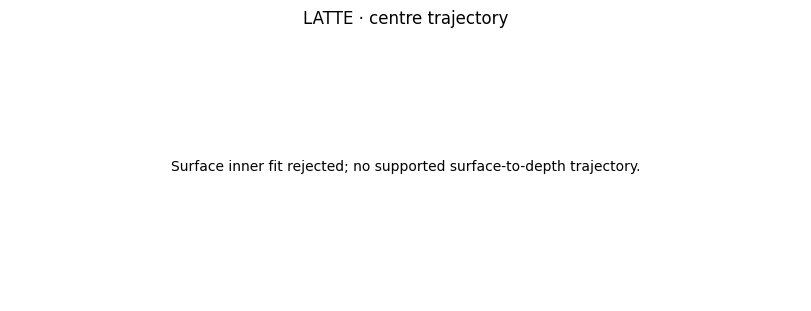

In [9]:
if SURFACE_FIT_OK:
    esp.plot_profiles(results)
else:
    esp._no_fit("LATTE · centre trajectory",
                "Surface inner fit rejected; no supported surface-to-depth trajectory.")
plt.show()

## Horizontal and three-dimensional reconstruction

Nearest measured levels are plotted, including rejected fits. Black arrows are observed ADCP flow; reconstructed fields and core contours appear only where the Gaussian fit passes. The 3-D view and fixed zonal/meridional sections use the same conventions as the other observation notebooks. The deepest ADCP bin is not the eddy bottom.

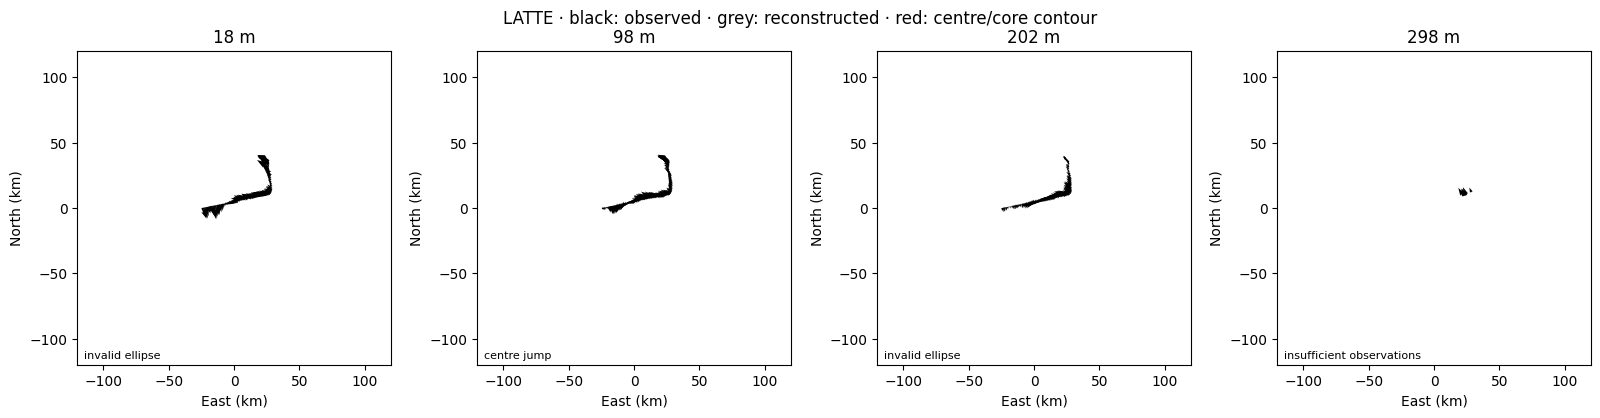

In [10]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()

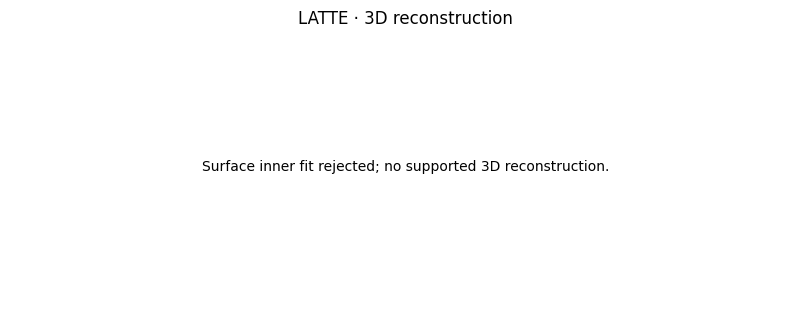

In [11]:
if SURFACE_FIT_OK:
    esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM,
                speed_max=VELOCITY_LIMIT)
else:
    esp._no_fit("LATTE · 3D reconstruction",
                "Surface inner fit rejected; no supported 3D reconstruction.")
plt.show()

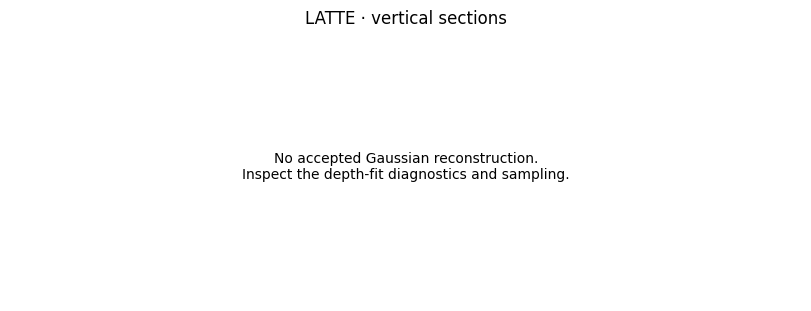

In [12]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()

## Export to scratch

Save accepted and rejected depth levels, plus the exact selected time window, starting guess, fit controls and backend fingerprint beside the voyage CSV.

In [13]:
SAVE_RESULTS = True
if SAVE_RESULTS:
    import json
    output = DATA_PATH.parent / "outputs"
    output.mkdir(parents=True, exist_ok=True)
    results.to_csv(output / "in2022_v06_latte_depth_fits.csv", index=False)
    provenance = dict(data_path=str(DATA_PATH), method="LATTE",
                      time_utc=TIME_UTC, adcp_window_hours=ADCP_WINDOW_HOURS,
                      selected_start_utc=str(selected.time.min()),
                      selected_end_utc=str(selected.time.max()),
                      selected_rows=len(selected), used_rows=len(fit_data),
                      origin_lon_lat=ORIGIN_LON_LAT,
                      fit_min_attendance=FIT_MIN_ATTENDANCE,
                      fit_settings=FIT, backend=backend_info)
    (output / "in2022_v06_latte_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
    print(f"Saved LATTE diagnostics to {output}")

Saved LATTE diagnostics to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2022_V06_adcp_trawler/outputs
